# Experimento de contexto físico: poblaciones estelares STARLIGHT

Clasificación binaria `temprana = 0.0` frente a `tardia = 1.0` usando **solo** la matriz de poblaciones estelares de STARLIGHT (fracción de luz y de masa actual por población BC03, `[2, 45]` aplanada a 90 valores) con un MLP.

Es un experimento de **contexto físico** (guía 11.4 y 22.6): las poblaciones derivan del mismo espectro FoV y correlacionan con la morfología por asociación astrofísica, no miden estructura. No es comparable con la clasificación visual/espectroscópica. La luz se renormaliza para sumar 1.

In [1]:
from __future__ import annotations

import copy
import json
import random
import sys
import time
from pathlib import Path
from typing import Any, Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score, f1_score
from torch import nn


def project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataloader.multimodal import build_dataloaders
from src.evaluate import evaluate_binary_classifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Proyecto: {ROOT}")
print(f"Dispositivo: {DEVICE}")

Proyecto: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias
Dispositivo: cuda


## Configuración e invariantes

- El split `data/processed/splits_seed42_obj-label_FoV.csv` es fijo: no se regenera dentro del experimento.
- La única modalidad activa es `populations` (`luz_pct` y `masa_actual_pct`, renormalizadas, aplanadas).
- La selección de checkpoints usa solo validación; `test` se consulta una única vez para el modelo seleccionado.
- Se usa una salida logit por galaxia y `BCEWithLogitsLoss`.

In [2]:
CONFIG: dict[str, Any] = {
    "experiment_name": "poblaciones_starlight_mlp",
    "seed": 42,
    "data": {
        "project_root": ROOT,
        "manifest": "data/galaxy_manifest.csv",
        "splits": "data/processed/splits_seed42_obj-label_FoV.csv",
        "modalities": ["populations"],
        "populations": {
            "dir": "data/processed/starlight/poblaciones_estelares",
            "channels": ["luz_pct", "masa_actual_pct"],
            "renormalize": True,
            "flatten": True,
        },
    },
    "model": {
        "hidden_dim": 128,
        "dropout": 0.3,
    },
    "training": {
        "batch_size": 32,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
        "epochs": 50,
        "learning_rate": 1e-4,
        "weight_decay": 1e-4,
        "early_stopping_patience": 8,
    },
    "selection_metric": "roc_auc",
}

RUN_DIR = ROOT / "models" / "experiments" / CONFIG["experiment_name"]
CHECKPOINT_PATH = RUN_DIR / "best_model.pt"
RESULTS_PATH = RUN_DIR / "results.json"
CONFIG_PATH = RUN_DIR / "config.json"

In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])
train_loader, validation_loader, test_loader = build_dataloaders(CONFIG)
loaders = {"train": train_loader, "validation": validation_loader, "test": test_loader}

for split_name, loader in loaders.items():
    labels = loader.dataset.frame["label"].value_counts()
    print(f"{split_name:10s} n={len(loader.dataset):5d}  temprana={labels.get('temprana', 0):5d}  tardia={labels.get('tardia', 0):5d}")

sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    if isinstance(value, torch.Tensor):
        print(f"{key:16s} {tuple(value.shape)} {value.dtype}")
    else:
        print(f"{key:16s} {type(value).__name__}")

train      n= 6545  temprana= 2467  tardia= 4078
validation n= 1403  temprana=  529  tardia=  874
test       n= 1403  temprana=  528  tardia=  875
id               list
label            (32,) torch.float32
populations      (32, 90) torch.float32


## Modelo: MLP sobre poblaciones

El baseline usa exclusivamente `populations` (90 valores: 45 fracciones de luz y 45 de masa actual). No hay máscara: las poblaciones están completas para todas las galaxias del split.

In [4]:
class PopulationClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, dropout: float) -> None:
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, batch: Mapping[str, Any]) -> torch.Tensor:
        return self.network(batch["populations"]).squeeze(1)


def build_model(config: Mapping[str, Any], batch: Mapping[str, Any]) -> nn.Module:
    model_config = config["model"]
    return PopulationClassifier(
        input_dim=batch["populations"].shape[1],
        hidden_dim=int(model_config["hidden_dim"]),
        dropout=float(model_config["dropout"]),
    )


model = build_model(CONFIG, sample_batch).to(DEVICE)
with torch.no_grad():
    batch_on_device = {
        key: value.to(DEVICE, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in sample_batch.items()
    }
    logits = model(batch_on_device)
if logits.shape != sample_batch["label"].shape:
    raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(sample_batch['label'].shape)}.")
assert torch.isfinite(logits).all()

In [5]:
def move_batch_to_device(batch: Mapping[str, Any], device: torch.device) -> dict[str, Any]:
    return {
        key: value.to(device, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in batch.items()
    }


def logits_from_model(model: nn.Module, batch: Mapping[str, Any]) -> torch.Tensor:
    logits = model(batch)
    expected_shape = batch["label"].shape
    if logits.shape != expected_shape:
        raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(expected_shape)}.")
    return logits


def train_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
) -> float:
    model.train()
    total_loss = 0.0
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(logits_from_model(model, batch), batch["label"])
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch["label"].numel()
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_true, all_pred, all_proba = [], [], []
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        logits = logits_from_model(model, batch)
        total_loss += criterion(logits, batch["label"]).item() * batch["label"].numel()
        probabilities = torch.sigmoid(logits)
        all_true.append(batch["label"].cpu().numpy())
        all_pred.append((probabilities >= 0.5).to(torch.int64).cpu().numpy())
        all_proba.append(probabilities.cpu().numpy())
    return (
        total_loss / len(loader.dataset),
        np.concatenate(all_true),
        np.concatenate(all_pred),
        np.concatenate(all_proba),
    )

In [6]:
def fit(
    model: nn.Module,
    train_loader: torch.utils.data.DataLoader,
    validation_loader: torch.utils.data.DataLoader,
    config: Mapping[str, Any],
    device: torch.device,
    checkpoint_path: Path,
) -> pd.DataFrame:
    training_config = config["training"]
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=training_config["learning_rate"],
        weight_decay=training_config["weight_decay"],
    )
    history: list[dict[str, float]] = []
    best_score = float("-inf")
    best_state: dict[str, torch.Tensor] | None = None
    epochs_without_improvement = 0

    for epoch in range(1, training_config["epochs"] + 1):
        started_at = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device)
        validation_loss, y_true, y_pred, y_proba = evaluate_epoch(
            model, validation_loader, criterion, device
        )
        metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
        score = float(metrics[config["selection_metric"]])
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "validation_accuracy": float(metrics["accuracy"]),
                "validation_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
                "validation_f1": f1_score(y_true, y_pred, zero_division=0),
                "validation_roc_auc": float(metrics["roc_auc"]),
                "seconds": time.perf_counter() - started_at,
            }
        )
        print(
            f"[{epoch:02d}/{training_config['epochs']}] "
            f"train_loss={train_loss:.4f} val_loss={validation_loss:.4f} "
            f"val_auc={metrics['roc_auc']:.4f}"
        )

        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= training_config["early_stopping_patience"]:
                print("Early stopping por validación.")
                break

    if best_state is None:
        raise RuntimeError("No se obtuvo un checkpoint de validación.")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state, "config": dict(config)}, checkpoint_path)
    return pd.DataFrame(history)


# Para entrenar después de implementar build_model:
model = build_model(CONFIG, sample_batch).to(DEVICE)
history = fit(model, train_loader, validation_loader, CONFIG, DEVICE, CHECKPOINT_PATH)

[01/50] train_loss=0.6703 val_loss=0.6351 val_auc=0.8528
[02/50] train_loss=0.5718 val_loss=0.5011 val_auc=0.8611
[03/50] train_loss=0.4639 val_loss=0.4445 val_auc=0.8676
[04/50] train_loss=0.4307 val_loss=0.4312 val_auc=0.8718
[05/50] train_loss=0.4195 val_loss=0.4256 val_auc=0.8740
[06/50] train_loss=0.4137 val_loss=0.4222 val_auc=0.8754
[07/50] train_loss=0.4119 val_loss=0.4200 val_auc=0.8766
[08/50] train_loss=0.4057 val_loss=0.4181 val_auc=0.8776
[09/50] train_loss=0.4076 val_loss=0.4164 val_auc=0.8789
[10/50] train_loss=0.4037 val_loss=0.4154 val_auc=0.8798
[11/50] train_loss=0.4053 val_loss=0.4149 val_auc=0.8806
[12/50] train_loss=0.4005 val_loss=0.4140 val_auc=0.8814
[13/50] train_loss=0.4006 val_loss=0.4131 val_auc=0.8823
[14/50] train_loss=0.3973 val_loss=0.4123 val_auc=0.8829
[15/50] train_loss=0.3948 val_loss=0.4116 val_auc=0.8835
[16/50] train_loss=0.3966 val_loss=0.4113 val_auc=0.8838
[17/50] train_loss=0.3932 val_loss=0.4111 val_auc=0.8842
[18/50] train_loss=0.3954 val_l

## Evaluación final y persistencia

Ejecute esta sección solo después de decidir la arquitectura e hiperparámetros usando validación. El split de `test` no participa en selección, calibración ni early stopping.

test_loss=0.3889  test_accuracy=0.8375  test_auc=0.8949
              precision    recall  f1-score      support
0.0            0.775735  0.799242  0.787313   528.000000
1.0            0.876601  0.860571  0.868512   875.000000
accuracy       0.837491  0.837491  0.837491     0.837491
macro avg      0.826168  0.829907  0.827913  1403.000000
weighted avg   0.838641  0.837491  0.837954  1403.000000


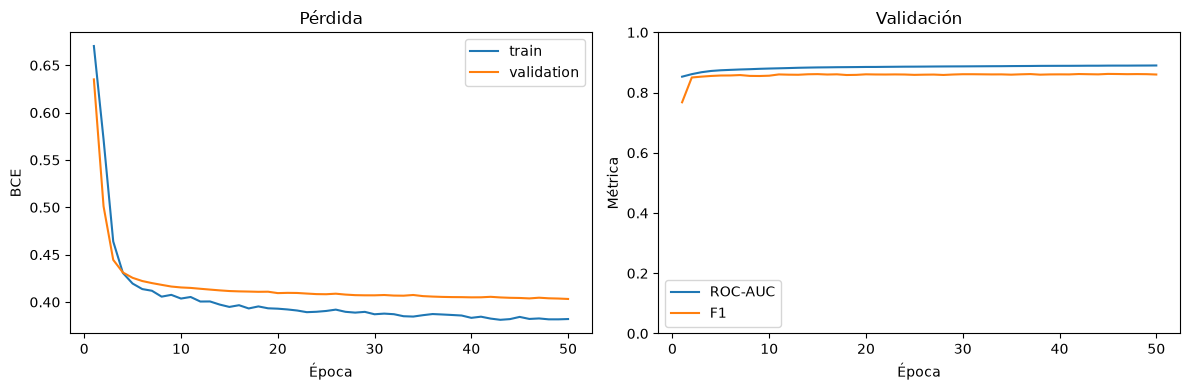

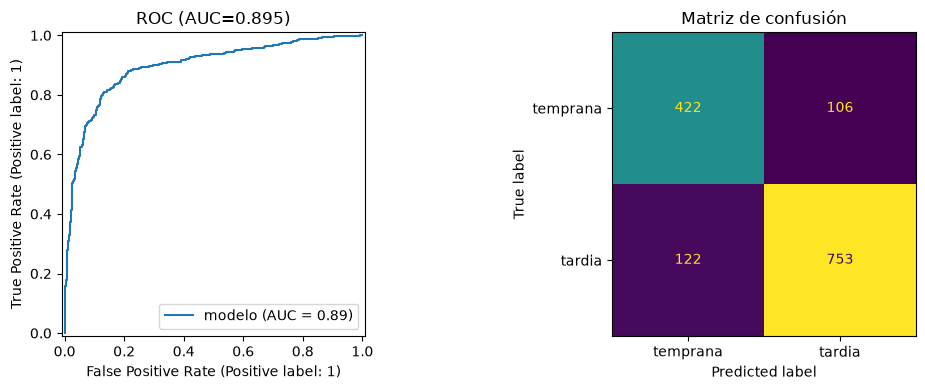

In [7]:
def plot_history(history: pd.DataFrame) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
    axes[0].set(title="Pérdida", xlabel="Época", ylabel="BCE")
    axes[0].legend()
    axes[1].plot(history["epoch"], history["validation_roc_auc"], label="ROC-AUC")
    axes[1].plot(history["epoch"], history["validation_f1"], label="F1")
    axes[1].set(title="Validación", xlabel="Época", ylabel="Métrica", ylim=(0, 1))
    axes[1].legend()
    figure.tight_layout()


def plot_binary_evaluation(y_true: np.ndarray, y_proba: np.ndarray, metrics: Mapping[str, Any]) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[0], name="modelo")
    axes[0].set_title(f"ROC (AUC={metrics['roc_auc']:.3f})")
    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=["temprana", "tardia"],
    ).plot(ax=axes[1], colorbar=False)
    axes[1].set_title("Matriz de confusión")
    figure.tight_layout()


def to_jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Mapping):
        return {str(key): to_jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(item) for item in value]
    return value


def save_run_artifacts(
    config: Mapping[str, Any], history: pd.DataFrame, test_metrics: Mapping[str, Any]
) -> None:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    with CONFIG_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(config), file, indent=2)
    history.to_csv(RUN_DIR / "history.csv", index=False)
    with RESULTS_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(test_metrics), file, indent=2)


# Después de seleccionar el experimento con validación:
criterion = nn.BCEWithLogitsLoss()
test_loss, y_test, y_test_pred, y_test_proba = evaluate_epoch(model, test_loader, criterion, DEVICE)
test_metrics = evaluate_binary_classifier(y_test, y_test_pred, y_test_proba)
print(f"test_loss={test_loss:.4f}  test_accuracy={test_metrics['accuracy']:.4f}  test_auc={test_metrics['roc_auc']:.4f}")
print(pd.DataFrame(test_metrics["report"]).T)
plot_history(history)
plot_binary_evaluation(y_test, y_test_proba, test_metrics)
save_run_artifacts(CONFIG, history, {"test_loss": test_loss, **test_metrics})

In [8]:
# Guarda
RUN_DIR.mkdir(parents=True, exist_ok=True)

experiment_data = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in model.state_dict().items()
    },
    "config": to_jsonable(CONFIG),
    "device": str(DEVICE),
    "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
    "history": history.to_dict(orient="records"),
    "test_metrics": to_jsonable(
        {"test_loss": test_loss, **test_metrics}
    ),
}

checkpoint_path = RUN_DIR / "experiment_checkpoint.pt"
torch.save(experiment_data, checkpoint_path)

with (RUN_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(CONFIG), file, indent=2)

history.to_csv(RUN_DIR / "history.csv", index=False)

with (RUN_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(
        to_jsonable({"test_loss": test_loss, **test_metrics}),
        file,
        indent=2,
    )

print(f"Modelo y resultados guardados en: {RUN_DIR}")
print(f"Checkpoint: {checkpoint_path}")

Modelo y resultados guardados en: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/poblaciones_starlight_mlp
Checkpoint: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/poblaciones_starlight_mlp/experiment_checkpoint.pt


# Save predictions

In [6]:
from torch.utils.data import DataLoader
import pandas as pd
from tqdm import tqdm

# Cargar el mejor checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE).eval()

THRESHOLD = 0.5
INT_TO_LABEL = {0: "temprana", 1: "tardia"}


@torch.no_grad()
def predict_split(dataset, split_name: str) -> pd.DataFrame:
    # El loader de train usa shuffle=True; se reconstruye sin shuffle para predecir.
    loader = DataLoader(
        dataset,
        batch_size=CONFIG["training"]["batch_size"],
        shuffle=False,
        num_workers=CONFIG["training"]["num_workers"],
        pin_memory=CONFIG["training"]["pin_memory"],
    )
    rows = []
    for batch in tqdm(loader, desc=f"Predict {split_name}", unit="batch", leave=False):
        ids = list(batch["id"])
        labels = batch["label"].to(torch.int64).numpy()
        logits = model(move_batch_to_device(batch, DEVICE))
        probas = torch.sigmoid(logits).cpu().numpy().astype(np.float64)
        rows.append(
            pd.DataFrame(
                {
                    "name": ids,
                    "split": split_name,
                    "y_true": labels,
                    "y_proba": probas,
                    "y_pred": (probas >= THRESHOLD).astype(np.int64),
                }
            )
        )
    return pd.concat(rows, ignore_index=True)


predictions = pd.concat(
    [
        predict_split(loader.dataset, split_name)
        for split_name, loader in loaders.items()
    ],
    ignore_index=True,
)
predictions["label"] = predictions["y_true"].map(INT_TO_LABEL)
predictions["pred_label"] = predictions["y_pred"].map(INT_TO_LABEL)
predictions["correct"] = predictions["y_true"] == predictions["y_pred"]
predictions = predictions[
    ["name", "split", "label", "y_true", "y_proba", "y_pred", "pred_label", "correct"]
]

PREDICTIONS_PATH = RUN_DIR / "predictions.csv"
predictions.to_csv(PREDICTIONS_PATH, index=False)
print(f"Guardado: {PREDICTIONS_PATH}  ({len(predictions)} filas)")
print(predictions.groupby("split")["correct"].mean().rename("accuracy"))
predictions.head()

Guardado: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/poblaciones_starlight_mlp/predictions.csv  (9351 filas)
split
test          0.837491
train         0.842934
validation    0.826800
Name: accuracy, dtype: float64


,name,split,label,y_true,y_proba,y_pred,pred_label,correct
0,manga-10001-12701,train,tardia,1,0.983070,1,tardia,True
1,manga-10001-1902,train,temprana,0,0.126360,0,temprana,True
2,manga-10001-3702,train,temprana,0,0.895603,1,tardia,False
3,manga-10001-3703,train,tardia,1,0.928295,1,tardia,True
4,manga-10001-3704,train,temprana,0,0.426292,0,temprana,True
